In [1]:
import json
import os
from datetime import date

DATA_FILE = "student_data.json"

DEFAULT_DATA = {
    "subjects": {
        "mathematics": {
            "name": "Mathematics",
            "study_hours": 12,
            "current_grade": 65,
            "target_grade": 85
        },
        "physics": {
            "name": "Physics",
            "study_hours": 8,
            "current_grade": 75,
            "target_grade": 90
        },
        "programming": {
            "name": "Programming",
            "study_hours": 6,
            "current_grade": 76,
            "target_grade": 90
        },
        "accounting": {
            "name": "Accounting",
            "study_hours": 10,
            "current_grade": 80,
            "target_grade": 95
        }
    },
    "daily_hours": 5,
    "study_plan": {},
    "progress_history": {}
}


def load_data():
    if os.path.exists(DATA_FILE):
        try:
            with open(DATA_FILE, "r") as file:
                saved_data = json.load(file)

            if not isinstance(saved_data.get("subjects"), dict):
                raise ValueError("Invalid subjects data")

            for key in DEFAULT_DATA:
                if key not in saved_data:
                    saved_data[key] = DEFAULT_DATA[key]

            print("Saved data loaded successfully.")
            return saved_data

        except (json.JSONDecodeError, ValueError):
            print("Could not read saved data. Using default data.")

    return {
        "subjects": {
            key: value.copy()
            for key, value in DEFAULT_DATA["subjects"].items()
        },
        "daily_hours": DEFAULT_DATA["daily_hours"],
        "study_plan": {},
        "progress_history": {}
    }


data = load_data()

subjects = data["subjects"]
daily_hours = float(data["daily_hours"])
study_plan = data["study_plan"]
progress_history = data["progress_history"]

print("Academic Planner data is ready.")
print("Number of subjects:", len(subjects)) 

Saved data loaded successfully.
Academic Planner data is ready.
Number of subjects: 5


In [2]:
def update_subject_analysis():
    for subject in subjects:
        current = subjects[subject]["current_grade"]
        target = subjects[subject]["target_grade"]
        gap = target - current

        if gap <= 0:
            status = "Target Reached"
        elif gap <= 10:
            status = "Close to Target"
        else:
            status = "Needs Improvement"

        if gap >= 15:
            priority = "High"
        else:
            priority = "Normal"

        subjects[subject]["grade_gap"] = gap
        subjects[subject]["status"] = status
        subjects[subject]["priority"] = priority


def recalculate_study_plan():
    global study_plan

    study_plan = {}

    if not subjects or daily_hours <= 0:
        return

    priorities = {}

    for subject, info in subjects.items():
        gap = max(
            0,
            info["target_grade"] - info["current_grade"]
        )

        priorities[subject] = max(gap, 1) ** 0.5

    total_priority = sum(priorities.values())

    for subject, priority in priorities.items():
        study_plan[subject] = round(
            daily_hours * priority / total_priority, 2
        )

    if study_plan:
        last_subject = list(study_plan.keys())[-1]

        difference = round(
            daily_hours - sum(study_plan.values()), 2
        )

        study_plan[last_subject] = round(
            study_plan[last_subject] + difference, 2
        ) 

In [3]:
def save_data():
    data["subjects"] = subjects
    data["daily_hours"] = daily_hours
    data["study_plan"] = study_plan
    data["progress_history"] = progress_history

    with open(DATA_FILE, "w") as file:
        json.dump(data, file, indent=4)

    print("Data saved successfully.")


def record_progress(subject, grade):
    today = str(date.today())

    if subject not in progress_history:
        progress_history[subject] = []

    records = progress_history[subject]

    if records and records[-1]["date"] == today:
        records[-1]["grade"] = grade
    else:
        records.append({
            "date": today,
            "grade": grade
        })


update_subject_analysis()
recalculate_study_plan()

for subject in subjects:
    if subject not in progress_history:
        progress_history[subject] = []

save_data() 

Data saved successfully.


In [4]:
def get_grade(prompt):
    while True:
        try:
            grade = float(input(prompt))

            if 0 <= grade <= 100:
                return grade

            print("Please enter a grade between 0 and 100.")

        except ValueError:
            print("Please enter a valid number.")


def get_positive_number(prompt):
    while True:
        try:
            number = float(input(prompt))

            if number >= 0:
                return number

            print("Please enter zero or a positive number.")

        except ValueError:
            print("Please enter a valid number.")


def get_subject_key(prompt):
    name = input(prompt).strip()
    return name.lower().replace(" ", "_") 

In [5]:
def show_dashboard():
    print("\n" + "=" * 42)
    print("           ACADEMIC DASHBOARD")
    print("=" * 42)

    if not subjects:
        print("No subjects available.")
        return

    total_subjects = len(subjects)

    average_grade = sum(
        subjects[s]["current_grade"] for s in subjects
    ) / total_subjects

    average_target = sum(
        subjects[s]["target_grade"] for s in subjects
    ) / total_subjects

    average_gap = average_target - average_grade

    progress = (
        average_grade / average_target * 100
        if average_target > 0 else 0
    )

    if progress >= 90:
        overall_status = "Excellent Progress"
    elif progress >= 75:
        overall_status = "Good Progress"
    else:
        overall_status = "Needs More Work"

    print("Total Subjects:", total_subjects)
    print("Daily Study Hours:", daily_hours)
    print("Average Current Grade:", round(average_grade, 2))
    print("Average Target Grade:", round(average_target, 2))
    print("Average Grade Gap:", round(average_gap, 2))
    print("Progress Toward Target:", round(progress, 2), "%")
    print("Overall Status:", overall_status)

    print("\n--- Subject Performance ---")

    for subject in subjects:
        info = subjects[subject]

        print(
            info["name"],
            "| Current:", info["current_grade"],
            "| Target:", info["target_grade"],
            "| Gap:", info["grade_gap"],
            "| Status:", info["status"],
            "| Priority:", info["priority"]
        )

    print("\n--- High Priority Subjects ---")

    high_subjects = [
        subjects[s]["name"]
        for s in subjects
        if subjects[s]["priority"] == "High"
    ]

    if high_subjects:
        for name in high_subjects:
            print("-", name)
    else:
        print("No high-priority subjects.")

    print("=" * 42) 

In [6]:
def add_subject():
    name = input("Enter subject name: ").strip()

    if not name:
        print("Subject name cannot be empty.")
        return

    key = name.lower().replace(" ", "_")

    if key in subjects:
        print("This subject already exists.")
        return

    current = get_grade("Enter current grade (0-100): ")
    target = get_grade("Enter target grade (0-100): ")
    hours = get_positive_number("Enter weekly study hours: ")

    subjects[key] = {
        "name": name,
        "study_hours": hours,
        "current_grade": current,
        "target_grade": target
    }

    progress_history[key] = []

    update_subject_analysis()
    record_progress(key, current)
    recalculate_study_plan()
    save_data()

    print("Subject added successfully!") 

In [7]:
def update_grade():
    subject = get_subject_key("Enter subject name: ")

    if subject not in subjects:
        print("Subject not found.")
        return

    grade = get_grade("Enter new current grade (0-100): ")

    subjects[subject]["current_grade"] = grade

    update_subject_analysis()
    record_progress(subject, grade)
    recalculate_study_plan()
    save_data()

    print("Grade updated successfully!")
    print("Grade Gap:", subjects[subject]["grade_gap"])
    print("Status:", subjects[subject]["status"])
    print("Priority:", subjects[subject]["priority"]) 

In [8]:
def update_target():
    subject = get_subject_key("Enter subject name: ")

    if subject not in subjects:
        print("Subject not found.")
        return

    target = get_grade("Enter new target grade (0-100): ")

    subjects[subject]["target_grade"] = target

    update_subject_analysis()
    recalculate_study_plan()
    save_data()

    print("Target grade updated successfully!")
    print("New Grade Gap:", subjects[subject]["grade_gap"])
    print("Priority:", subjects[subject]["priority"]) 

In [9]:
def update_daily_hours():
    global daily_hours

    hours = get_positive_number(
        "Enter available study hours per day: "
    )

    daily_hours = hours

    recalculate_study_plan()
    save_data()

    print("Daily study hours updated.")
    print("New daily hours:", daily_hours) 

In [10]:
def delete_subject():
    subject = get_subject_key("Enter subject name to delete: ")

    if subject not in subjects:
        print("Subject not found.")
        return

    deleted_name = subjects[subject]["name"]

    del subjects[subject]

    study_plan.pop(subject, None)
    progress_history.pop(subject, None)

    update_subject_analysis()
    recalculate_study_plan()
    save_data()

    print("Subject deleted:", deleted_name) 

In [11]:
def show_study_plan():
    print("\n" + "=" * 42)
    print("           SMART STUDY PLAN")
    print("=" * 42)

    if not subjects:
        print("No subjects available.")
        return

    for subject in subjects:
        info = subjects[subject]

        print(
            info["name"],
            "| Priority:", info["priority"],
            "| Planned Hours:", study_plan.get(subject, 0)
        )

    print("-" * 42)
    print("Available Hours:", daily_hours)
    print("Planned Hours:", round(sum(study_plan.values()), 2))
    print("=" * 42) 

In [12]:
def show_progress():
    subject = get_subject_key("Enter subject name: ")

    if subject not in subjects:
        print("Subject not found.")
        return

    records = progress_history.get(subject, [])

    print("\n--- Progress History ---")
    print("Subject:", subjects[subject]["name"])

    if not records:
        print("No progress records yet.")
        return

    for record in records:
        print(
            "Date:", record["date"],
            "| Grade:", record["grade"]
        )

    if len(records) >= 2:
        change = records[-1]["grade"] - records[0]["grade"]

        print("Overall Grade Change:", round(change, 2))

        if change > 0:
            print("Result: Improvement")
        elif change < 0:
            print("Result: Decline")
        else:
            print("Result: No Change") 

In [13]:
def show_charts():
    if not subjects:
        print("No subjects available for charts.")
        return

    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("Matplotlib is not available.")
        return

    names = [subjects[s]["name"] for s in subjects]
    current = [subjects[s]["current_grade"] for s in subjects]
    targets = [subjects[s]["target_grade"] for s in subjects]
    gaps = [subjects[s]["grade_gap"] for s in subjects]

    # Chart 1: Current grades and target grades
    positions = list(range(len(names)))
    width = 0.35

    plt.figure(figsize=(10, 5))
    plt.bar(
        [p - width / 2 for p in positions],
        current,
        width=width,
        label="Current Grade"
    )
    plt.bar(
        [p + width / 2 for p in positions],
        targets,
        width=width,
        label="Target Grade"
    )

    plt.xticks(positions, names, rotation=20)
    plt.ylabel("Grade")
    plt.title("Current Grade vs Target Grade")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Chart 2: Grade gaps
    plt.figure(figsize=(9, 5))
    plt.bar(names, gaps)
    plt.ylabel("Grade Gap")
    plt.title("Grade Gap by Subject")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

    # Chart 3: Daily study plan
    plan_hours = [study_plan.get(s, 0) for s in subjects]

    plt.figure(figsize=(9, 5))
    plt.bar(names, plan_hours)
    plt.ylabel("Hours")
    plt.title("Daily Study Plan")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

    # Chart 4: Grade progress over time
    has_history = False

    plt.figure(figsize=(9, 5))

    for subject in subjects:
        records = progress_history.get(subject, [])

        if records:
            dates = [record["date"] for record in records]
            grades = [record["grade"] for record in records]

            plt.plot(
                dates,
                grades,
                marker="o",
                label=subjects[subject]["name"]
            )
            has_history = True

    if has_history:
        plt.xlabel("Date")
        plt.ylabel("Grade")
        plt.title("Grade Progress Over Time")
        plt.legend()
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    else:
        plt.close()
        print("No progress history available for a chart yet.") 


Academic Planner & Study Analytics is ready!
Initial subjects: 5
Daily study hours: 4.0

    ACADEMIC PLANNER & STUDY ANALYTICS
1. View Academic Dashboard
2. Add Subject
3. Update Current Grade
4. Update Target Grade
5. Update Daily Study Hours
6. Delete Subject
7. View Progress History
8. View Smart Study Plan
9. Show Charts
10. Save Data
11. Exit



Choose an option (1-11):  1



           ACADEMIC DASHBOARD
Total Subjects: 5
Daily Study Hours: 4.0
Average Current Grade: 75.2
Average Target Grade: 88.0
Average Grade Gap: 12.8
Progress Toward Target: 85.45 %
Overall Status: Good Progress

--- Subject Performance ---
Mathematics | Current: 72.0 | Target: 85.0 | Gap: 13.0 | Status: Needs Improvement | Priority: Normal
Physics | Current: 78.0 | Target: 90.0 | Gap: 12.0 | Status: Needs Improvement | Priority: Normal
Programming | Current: 76 | Target: 90 | Gap: 14 | Status: Needs Improvement | Priority: Normal
Accounting | Current: 80 | Target: 95 | Gap: 15 | Status: Needs Improvement | Priority: High
Chemistry | Current: 70.0 | Target: 80.0 | Gap: 10.0 | Status: Close to Target | Priority: Normal

--- High Priority Subjects ---
- Accounting

    ACADEMIC PLANNER & STUDY ANALYTICS
1. View Academic Dashboard
2. Add Subject
3. Update Current Grade
4. Update Target Grade
5. Update Daily Study Hours
6. Delete Subject
7. View Progress History
8. View Smart Study Plan
9


Choose an option (1-11):  8



           SMART STUDY PLAN
Mathematics | Priority: Normal | Planned Hours: 0.81
Physics | Priority: Normal | Planned Hours: 0.78
Programming | Priority: Normal | Planned Hours: 0.84
Accounting | Priority: High | Planned Hours: 0.87
Chemistry | Priority: Normal | Planned Hours: 0.7
------------------------------------------
Available Hours: 4.0
Planned Hours: 4.0

    ACADEMIC PLANNER & STUDY ANALYTICS
1. View Academic Dashboard
2. Add Subject
3. Update Current Grade
4. Update Target Grade
5. Update Daily Study Hours
6. Delete Subject
7. View Progress History
8. View Smart Study Plan
9. Show Charts
10. Save Data
11. Exit



Choose an option (1-11):  9


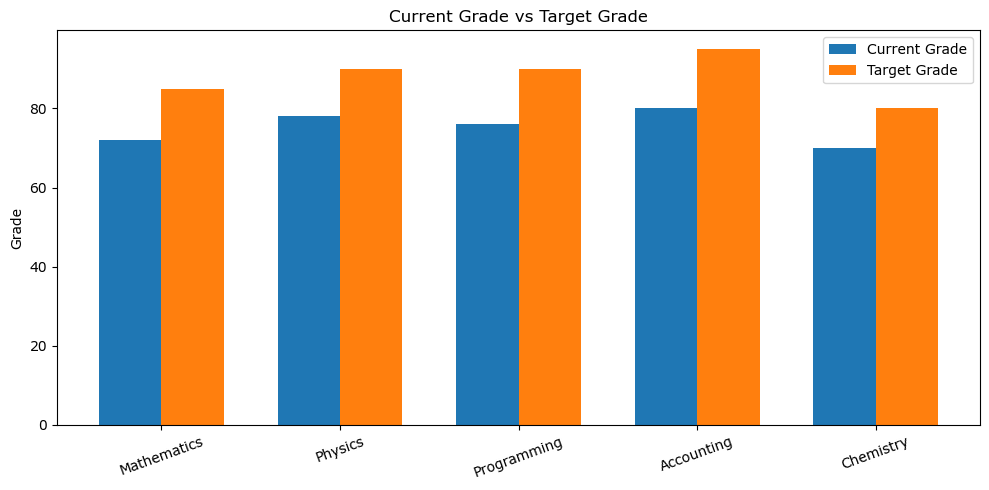

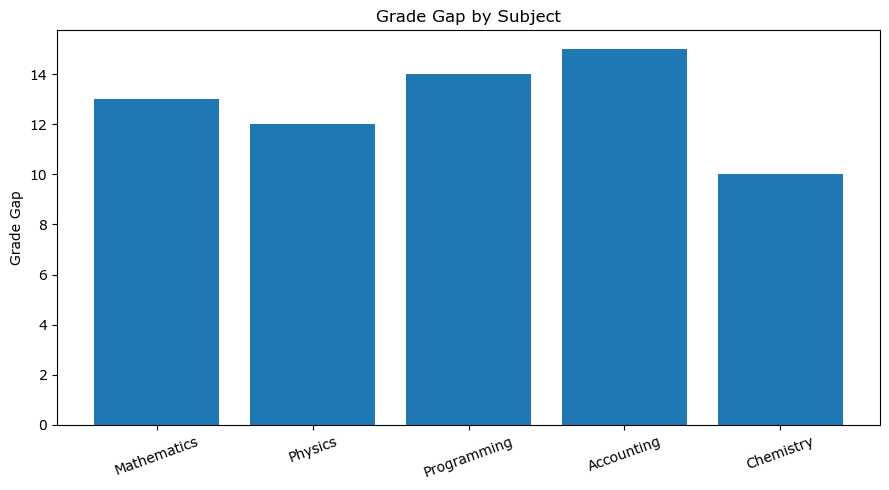

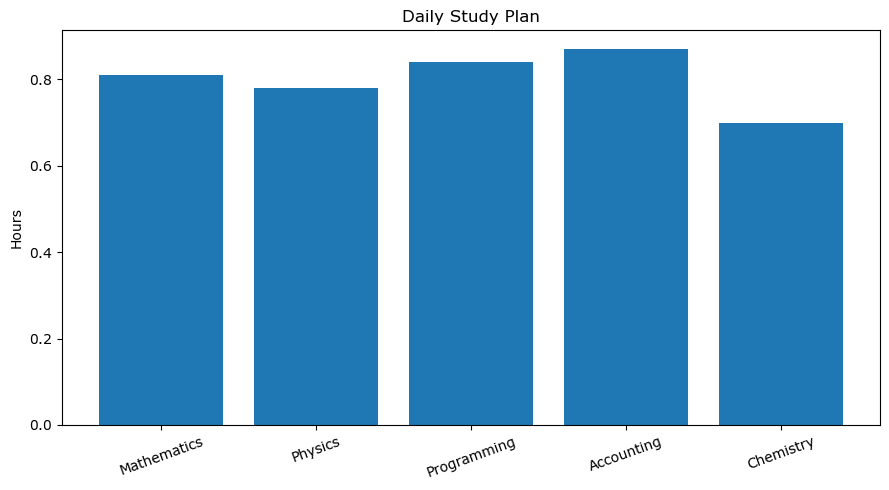

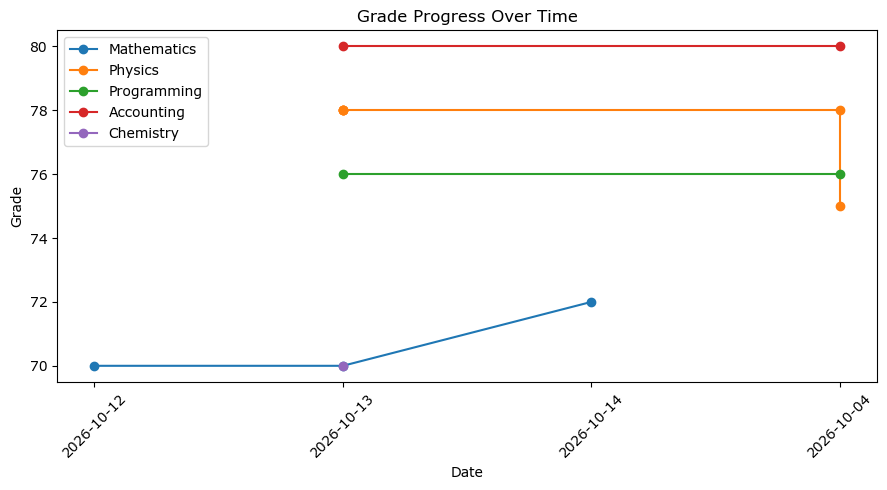


    ACADEMIC PLANNER & STUDY ANALYTICS
1. View Academic Dashboard
2. Add Subject
3. Update Current Grade
4. Update Target Grade
5. Update Daily Study Hours
6. Delete Subject
7. View Progress History
8. View Smart Study Plan
9. Show Charts
10. Save Data
11. Exit



Choose an option (1-11):  11


Data saved successfully.
Thank you for using Academic Planner!


In [14]:
def main():
    while True:
        print("\n" + "=" * 42)
        print("    ACADEMIC PLANNER & STUDY ANALYTICS")
        print("=" * 42)

        print("1. View Academic Dashboard")
        print("2. Add Subject")
        print("3. Update Current Grade")
        print("4. Update Target Grade")
        print("5. Update Daily Study Hours")
        print("6. Delete Subject")
        print("7. View Progress History")
        print("8. View Smart Study Plan")
        print("9. Show Charts")
        print("10. Save Data")
        print("11. Exit")

        choice = input("\nChoose an option (1-11): ").strip()

        if choice == "1":
            show_dashboard()

        elif choice == "2":
            add_subject()

        elif choice == "3":
            update_grade()

        elif choice == "4":
            update_target()

        elif choice == "5":
            update_daily_hours()

        elif choice == "6":
            delete_subject()

        elif choice == "7":
            show_progress()

        elif choice == "8":
            show_study_plan()

        elif choice == "9":
            show_charts()

        elif choice == "10":
            save_data()

        elif choice == "11":
            save_data()
            print("Thank you for using Academic Planner!")
            break

        else:
            print("Invalid choice. Please enter a number from 1 to 11.")


print("\nAcademic Planner & Study Analytics is ready!")
print("Initial subjects:", len(subjects))
print("Daily study hours:", daily_hours)

main() 